# B3 — Count neighbouring pairs and estimate transition probabilities

**P2 deliverables:** reusable `src/indus/ngrams.py`, a transition heatmap and
a carefully qualified comparison with the IM77 table. Select `.venv/bin/python`
and run all cells. This notebook runs independently of B1/B2 branches.

We use `load_sequences()` and keep its reading order. IDs are Wells; IM77 uses
Mahadevan and a different corpus. No raw files are edited. This is an unsmoothed
descriptive model of the full corpus, **not a held-out prediction score**.
There is no random sampling, training split or random seed in B3.

## 1. Work through the pairs by hand

```text
[151, 105, 151, 740] → (151,105), (105,151), (151,740)
[151, 740]           → (151,740)
[151, 151, 740]      → (151,151), (151,740)
```

These invented sequences yield six pair occurrences but four distinct pair
types. Repeats count; direction matters; pairs never cross text boundaries.
For sign 151 there are five outgoing pairs: 3 to 740, 1 to 105 and 1 to itself.
The next-sign probabilities are 0.6, 0.2 and 0.2.

`P(Y | X) = count(X → Y) / sum_Z count(X → Z)`.
The denominator counts occurrences with a successor, not all X tokens.
A final X contributes no outgoing pair. First-order Markov means that this
model conditions on the current sign only, ignoring earlier history.

In [1]:
import sys
import json
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from indus.data import (load_sequences, load_im77_ngrams, wells_to_mahadevan,
                        REPO_ROOT, SEQUENCES_FILE, BIGRAMS_FILE, MAPPING_FILE)
from indus.ngrams import (count_ngrams, bigram_table, transition_matrices,
                         compare_im77_bigrams)

print("Interpreter:", sys.executable)
toy = [[151, 105, 151, 740], [151, 740], [151, 151, 740]]
assert count_ngrams(toy) == {(151,105): 1, (105,151): 1, (151,740): 3, (151,151): 1}
toy_counts, toy_probabilities = transition_matrices(toy)
assert toy_probabilities.loc[151,740] == 0.6
assert toy_probabilities.loc[151,105] == 0.2
assert toy_probabilities.loc[740].isna().all()
display(bigram_table(toy))
display(toy_probabilities)

Interpreter: /home/devambhavsar/ML/AI_Project/.venv/bin/python


,current_wells_id,next_wells_id,count
0,151,740,3
1,105,151,1
2,151,105,1
3,151,151,1


next_wells_id,105,151,740
current_wells_id,,,
105,0.0,1.0,0.0
151,0.2,0.2,0.6
740,NaN,NaN,NaN


### How the code builds a pair

`range(len(sequence) - n + 1)` supplies every valid starting position for an
n-sign window. For length 4 and n=2, the positions are 0, 1, 2.
`sequence[start:start+n]` takes that slice. `tuple(...)` turns the list into
a fixed sequence that can be used as a `Counter` key. A two-sign tuple stores
a whole pair, not two independent counts. Adding one counts its occurrence.

The window loop is inside the inscription loop, so we never join texts.
`count_ngrams()` also supports n=1 or n=3 for later work; B3 uses n=2.
Empty sequences are rejected, while a sequence shorter than n contributes
no windows. `bigram_table()` ranks counts, breaking ties by ascending pair IDs.

## 2. Count real pairs and create the full matrices

Count matrix row = current sign; column = next sign. Both axes contain all 568
observed Wells IDs, in ascending order. These IDs label rows; a row number is
not a sign ID. `counts.loc[X,Y]` accesses the count for that specific pair.

Divide each row by its outgoing total. Defined probability rows sum to one.
Signs with no observed successor have an entirely **NaN** row: their conditional
distribution is undefined. We do not invent a uniform distribution or present
a zero row as a valid distribution. In defined rows, unseen pairs have zero
probability; B5 will address smoothing.

In [2]:
sequences = load_sequences()
pairs = count_ngrams(sequences)
ranked_pairs = bigram_table(sequences)
counts, probabilities = transition_matrices(sequences)
outgoing = counts.sum(axis=1)
defined = outgoing > 0
total_pairs = sum(pairs.values())
assert len(sequences) == 1837
assert total_pairs == sum(len(s) - 1 for s in sequences) == 8359 - 1837 == 6522
assert counts.shape == (568,568)
assert int(counts.to_numpy().sum()) == total_pairs
np.testing.assert_allclose(probabilities.loc[defined].sum(axis=1), 1, atol=1e-12)
assert probabilities.loc[~defined].isna().all().all()
print("Pair occurrences:", total_pairs)
print("Distinct pair types:", len(pairs))
print("Signs with observed successors:", int(defined.sum()))
print("Signs with undefined probability rows:", int((~defined).sum()))
display(ranked_pairs.head(20))
print("Jar sign outgoing count:", int(outgoing.loc[740]))
print("Jar's most frequent observed successors:")
display(probabilities.loc[740].sort_values(ascending=False).head(10))

Pair occurrences: 6522
Distinct pair types: 2751
Signs with observed successors: 526
Signs with undefined probability rows: 42


,current_wells_id,next_wells_id,count
0,861,2,114
1,817,2,91
2,740,400,88
3,820,2,68
4,760,740,66
5,100,740,65
6,740,90,64
7,705,33,57
8,176,740,49
9,920,60,45


Jar sign outgoing count: 255
Jar's most frequent observed successors:


next_wells_id
400    0.345098
90     0.250980
1      0.062745
679    0.039216
151    0.023529
565    0.019608
140    0.015686
61     0.011765
790    0.011765
550    0.011765
Name: 740, dtype: float64

## 3. Heatmap of transitions among the 15 most frequent signs

Select signs by their overall token frequency (ties by smaller ID). Compute the
full 568-sign probabilities **before** selecting rows and columns for display.
A displayed row can sum to less than 1 because the omitted successors retain
their probability mass. We do not renormalise this crop.

Colour is next-sign probability. Cell labels give probability to two decimals
and show raw counts in parentheses. Small positive probabilities below 0.01
are labelled `<0.01`; blank cells are unobserved pairs with zero probability. High probability from one observation is
weaker evidence than the same probability from many observations. Grey cells
indicate undefined rows if any selected sign has no outgoing observations.

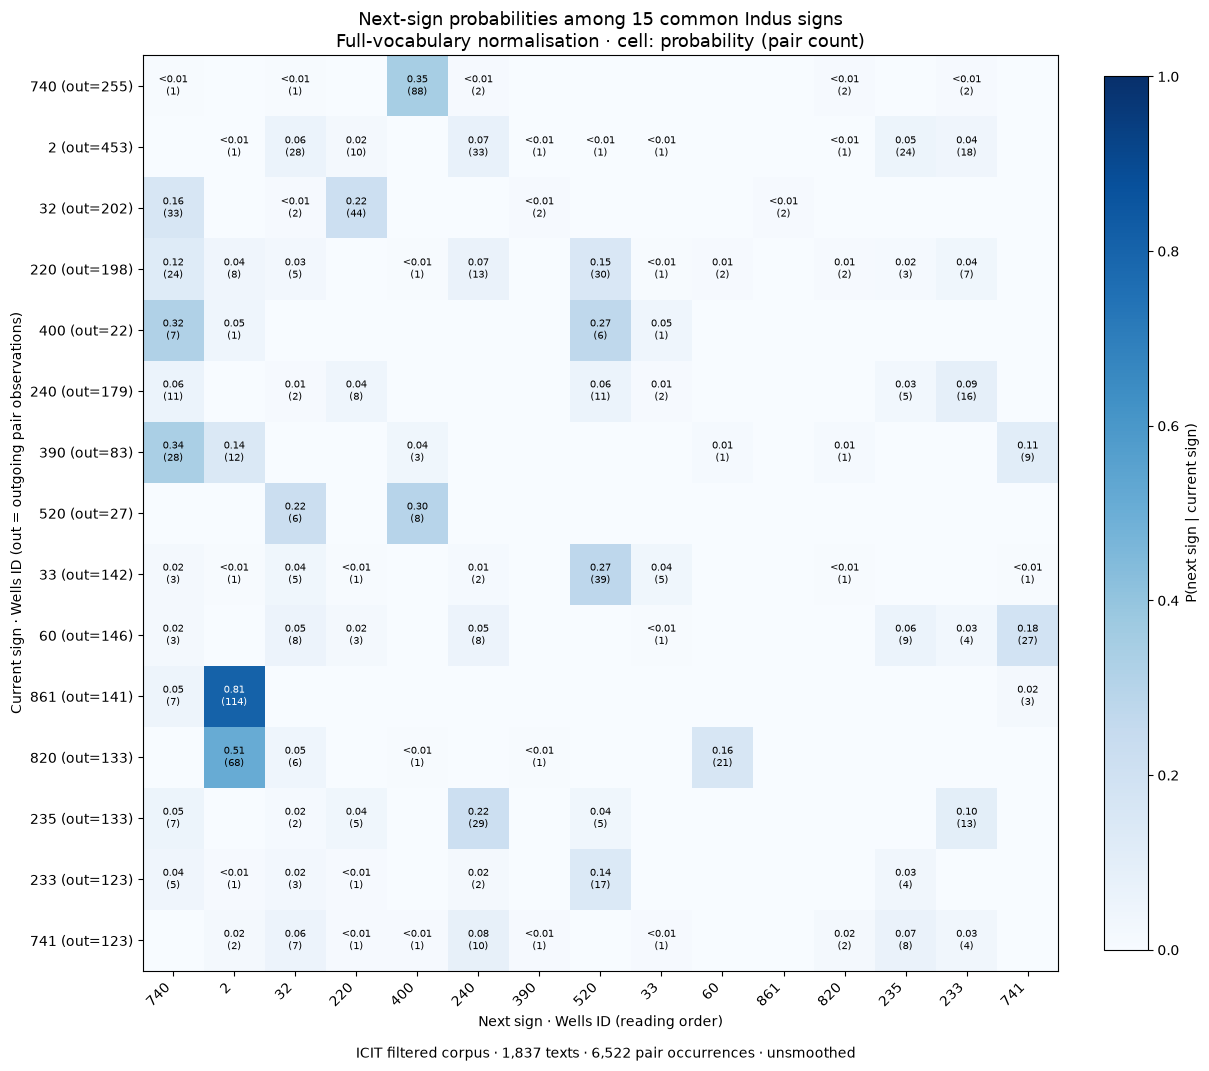

Displayed probability mass per selected row (remaining mass goes to omitted signs):


current_wells_id
740    0.376471
2      0.260486
32     0.410891
220    0.484848
400    0.681818
240    0.307263
390    0.650602
520    0.518519
33     0.408451
60     0.431507
861    0.879433
820    0.729323
235    0.458647
233    0.268293
741    0.300813
dtype: float64

In [3]:
tokens = Counter(sign for sequence in sequences for sign in sequence)
top_signs = [sign for sign, count in sorted(tokens.items(), key=lambda item: (-item[1], item[0]))[:15]]
view = probabilities.loc[top_signs, top_signs]
view_counts = counts.loc[top_signs, top_signs]
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#D9D9D9")
fig, ax = plt.subplots(figsize=(12,11), layout="constrained")
plot = ax.imshow(np.ma.masked_invalid(view.to_numpy()), cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(top_signs)), [str(s) for s in top_signs], rotation=45, ha="right")
ax.set_yticks(range(len(top_signs)), [f"{s} (out={int(outgoing.loc[s])})" for s in top_signs])
ax.set_xlabel("Next sign · Wells ID (reading order)")
ax.set_ylabel("Current sign · Wells ID (out = outgoing pair observations)")
ax.set_title("Next-sign probabilities among 15 common Indus signs\n"
             "Full-vocabulary normalisation · cell: probability (pair count)", fontsize=13)
for i in range(len(top_signs)):
    for j in range(len(top_signs)):
        value = view.iloc[i,j]
        count = int(view_counts.iloc[i,j])
        if np.isnan(value):
            label = "—"
        elif count:
            probability_label = "<0.01" if value < 0.01 else f"{value:.2f}"
            label = f"{probability_label}\n({count})"
        else:
            label = ""
        ax.text(j,i,label,ha="center",va="center",fontsize=7,
                color="white" if not np.isnan(value) and value > 0.55 else "black")
colorbar = fig.colorbar(plot, ax=ax, shrink=0.8)
colorbar.set_label("P(next sign | current sign)")
fig.text(0.5, 0.005, "ICIT filtered corpus · 1,837 texts · 6,522 pair occurrences · unsmoothed",
         ha="center", fontsize=10)
figures = REPO_ROOT / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / "b3_transitions.png", dpi=180)
plt.show()
plt.close(fig)
print("Displayed probability mass per selected row (remaining mass goes to omitted signs):")
display(view.sum(axis=1, min_count=1))

## 4. Compare patterns with IM77 without mixing numbering systems

The IM77 source columns are `left_sign,right_sign,count`, **visual order**.
For reading order, a row `(left,right)` becomes `(right,left)`. For example
visual `(99,267)` means reading-order `267 → 99`.

Convert ICIT pairs only through `wells_to_mahadevan()`. Accept a pair only if
both Wells signs map to exactly one Mahadevan ID. Exclude missing or ambiguous
mappings and report the lost coverage. Pool different eligible Wells pairs
mapping to the same Mahadevan pair; do not pretend they are separate IM77 pairs.

This is a comparison with a different corpus using a non-authoritative hand
mapping. ICIT mapped counts are partial eligible counts. Neither counts nor
ranks are expected to match exactly. Presence/absence and top-pair examples
are evidence of pattern agreement or disagreement, not a pass/fail proof.
An absent pair means absent from this supplied IM77 table, not impossible.

For the top original Wells pairs, we also list candidate Mahadevan pairs
that occur in IM77. For ambiguous mappings this shows compatibility only:
it does not choose the correct ID or justify assigning counts to it.

In [4]:
mapping = wells_to_mahadevan()
im77_visual = load_im77_ngrams(2)
assert len(im77_visual) == 2730
assert im77_visual.iloc[0].tolist() == [99,267,290]
compared, coverage = compare_im77_bigrams(pairs, mapping, im77_visual)
assert sum(coverage[s + "_pair_types"] for s in ("eligible","ambiguous","unmapped")) == len(pairs)
assert sum(coverage[s + "_pair_tokens"] for s in ("eligible","ambiguous","unmapped")) == total_pairs
assert int(compared["icit_unambiguous_count"].sum()) == coverage["eligible_pair_tokens"]

# Also expose mapping eligibility for the highest-count original Wells pairs.
top_pair_mapping = ranked_pairs.head(20).copy()
def candidates(sign):
    return " ".join(str(value) for value in sorted(mapping.get(sign, set())))
top_pair_mapping["current_mahadevan_candidates"] = top_pair_mapping["current_wells_id"].map(candidates)
top_pair_mapping["next_mahadevan_candidates"] = top_pair_mapping["next_wells_id"].map(candidates)
def mapping_status(row):
    first = mapping.get(row.current_wells_id, set())
    second = mapping.get(row.next_wells_id, set())
    if not first or not second:
        return "unmapped"
    return "eligible" if len(first) == len(second) == 1 else "ambiguous"
top_pair_mapping["mapping_status"] = [mapping_status(row) for row in top_pair_mapping.itertuples()]

im77_reading_pairs = {(int(row.right_sign), int(row.left_sign))
                      for row in im77_visual.itertuples(index=False)}
def compatible_pairs(row):
    first = mapping.get(row.current_wells_id, set())
    second = mapping.get(row.next_wells_id, set())
    return "; ".join(f"{a}->{b}" for a in sorted(first) for b in sorted(second)
                     if (a,b) in im77_reading_pairs)
top_pair_mapping["im77_candidate_pairs_present"] = [compatible_pairs(row)
                                                   for row in top_pair_mapping.itertuples()]
assert (267,99) in im77_reading_pairs  # Visual first row (99,267) was reversed.
print("Mapping coverage:")
display(pd.Series(coverage))
print("Highest-count Wells pairs and their mapping eligibility:")
display(top_pair_mapping)
print("Highest-count pooled eligible Mahadevan pairs, compared in reading order:")
display(compared.head(20))
eligible_tokens = coverage["eligible_pair_tokens"]
support = coverage["eligible_pair_tokens_present_in_im77"]
print(f"Pair occurrences eligible for comparison: {eligible_tokens}/{total_pairs} = {eligible_tokens/total_pairs:.2%}")
print(f"Eligible occurrences whose pair is also in IM77: {support}/{eligible_tokens} = {support/eligible_tokens:.2%}")

Mapping coverage:


observed_pair_types                     2751
observed_pair_tokens                    6522
eligible_pair_types                     1517
eligible_pair_tokens                    3802
ambiguous_pair_types                     768
ambiguous_pair_tokens                   2092
unmapped_pair_types                      466
unmapped_pair_tokens                     628
mapped_mahadevan_pair_types             1371
mapped_types_present_in_im77            1042
eligible_pair_tokens_present_in_im77    3440
dtype: int64

Highest-count Wells pairs and their mapping eligibility:


,current_wells_id,next_wells_id,count,current_mahadevan_candidates,next_mahadevan_candidates,mapping_status,im77_candidate_pairs_present
0,861,2,114,267,99 100,ambiguous,267->99
1,817,2,91,267,99 100,ambiguous,267->99
2,740,400,88,342,176,eligible,342->176
3,820,2,68,391,99 100,ambiguous,391->99
4,760,740,66,347 358,342,ambiguous,347->342; 358->342
5,100,740,65,8,342,eligible,8->342
6,740,90,64,342,1,eligible,342->1
7,705,33,57,336,89,eligible,336->89
8,176,740,49,48,342,eligible,48->342
9,920,60,45,293,123,eligible,293->123


Highest-count pooled eligible Mahadevan pairs, compared in reading order:


,current_mahadevan_id,next_mahadevan_id,icit_unambiguous_count,im77_count,in_im77
0,342,176,88,184,True
1,336,89,87,126,True
2,8,342,65,93,True
3,342,1,64,87,True
4,48,342,53,114,True
5,293,123,45,54,True
6,87,59,44,63,True
7,89,211,39,44,True
8,216,254,37,29,True
9,171,59,35,76,True


Pair occurrences eligible for comparison: 3802/6522 = 58.30%
Eligible occurrences whose pair is also in IM77: 3440/3802 = 90.48%


## 5. Reproducible checks and exports

`scripts/check_b3.py` runs nine checks without requiring notebook execution:
toy probabilities, boundaries, repeats, overlapping windows, invalid inputs,
no-successor rows, denominator handling, reversal, mapping direction and
many-to-one pooling, plus independently calculated real-corpus counts.
Run `.venv/bin/python scripts/check_b3.py` from the repo root.

On real data, each row total must equal that sign's total tokens minus its
final-position count. Each column total equals tokens minus its initial-position
count. Reversing all sequences transposes the **count** matrix. The probability
matrix is not generally its transpose, because normalisation denominators change.

Undefined distributions stay NaN in the exported probability CSV (blank cells),
accompanied by `outgoing_counts.csv` explicitly naming defined rows. These do
not sum to zero or become uniform. B5 will implement an explicit smoothing policy.

In [5]:
independent = {}
for sequence in sequences:
    for i in range(1,len(sequence)):
        pair = (sequence[i-1], sequence[i])
        independent[pair] = independent.get(pair,0) + 1
assert dict(pairs) == independent
starts = Counter(s[0] for s in sequences)
ends = Counter(s[-1] for s in sequences)
for sign in counts.index:
    assert int(counts.loc[sign].sum()) == tokens[sign] - ends[sign]
    assert int(counts[sign].sum()) == tokens[sign] - starts[sign]
reverse_counts, _ = transition_matrices([s[::-1] for s in sequences])
np.testing.assert_array_equal(reverse_counts.to_numpy(), counts.to_numpy().T)

processed = REPO_ROOT / "data/processed/b3"
processed.mkdir(parents=True, exist_ok=True)
ranked_pairs.to_csv(processed / "bigram_counts.csv", index=False)
counts.to_csv(processed / "transition_counts.csv")
probabilities.to_csv(processed / "transition_probabilities.csv", na_rep="")
row_status = pd.DataFrame({"wells_id": counts.index, "outgoing_count": outgoing.values,
                           "probability_defined": defined.values})
row_status.to_csv(processed / "outgoing_counts.csv", index=False)
compared.to_csv(processed / "im77_comparison.csv", index=False)
top_pair_mapping.to_csv(processed / "top_pairs_mapping.csv", index=False)
saved = pd.read_csv(processed / "transition_probabilities.csv", index_col=0)
np.testing.assert_allclose(saved.to_numpy(), probabilities.to_numpy(), atol=1e-12, equal_nan=True)
assert list(saved.index) == list(probabilities.index)
assert [int(c) for c in saved.columns] == list(probabilities.columns)
pd.testing.assert_frame_equal(pd.read_csv(processed / "bigram_counts.csv"),ranked_pairs)
summary = {
    "dataset": "ICIT 1837 filtered unique inscriptions", "numbering": "Wells", "order": "reading",
    "n_sequences": len(sequences), "n_tokens": sum(tokens.values()), "n_types": len(tokens),
    "bigram_tokens": total_pairs, "bigram_types": len(pairs),
    "defined_rows": int(defined.sum()), "undefined_rows": int((~defined).sum()),
    "undefined_wells_ids": [int(s) for s in counts.index[~defined]],
    "jar_outgoing_count": int(outgoing.loc[740]), "heatmap_wells_ids": top_signs,
    "mapping_coverage": coverage,
    "sources": {str(p.relative_to(REPO_ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                for p in (SEQUENCES_FILE,BIGRAMS_FILE,MAPPING_FILE)}
}
(processed / "summary.json").write_text(json.dumps(summary,indent=2) + "\n")
print("All notebook checks passed; exports:", processed)
print(json.dumps(summary,indent=2))

All notebook checks passed; exports: /home/devambhavsar/ML/AI_Project/data/processed/b3
{
  "dataset": "ICIT 1837 filtered unique inscriptions",
  "numbering": "Wells",
  "order": "reading",
  "n_sequences": 1837,
  "n_tokens": 8359,
  "n_types": 568,
  "bigram_tokens": 6522,
  "bigram_types": 2751,
  "defined_rows": 526,
  "undefined_rows": 42,
  "undefined_wells_ids": [
    45,
    105,
    106,
    116,
    138,
    157,
    161,
    173,
    200,
    203,
    224,
    256,
    294,
    307,
    324,
    375,
    409,
    410,
    423,
    426,
    427,
    429,
    430,
    461,
    481,
    506,
    512,
    526,
    685,
    712,
    718,
    748,
    749,
    822,
    842,
    855,
    866,
    869,
    875,
    911,
    930,
    932
  ],
  "jar_outgoing_count": 255,
  "heatmap_wells_ids": [
    740,
    2,
    32,
    220,
    400,
    240,
    390,
    520,
    33,
    60,
    861,
    820,
    235,
    233,
    741
  ],
  "mapping_coverage": {
    "observed_pair_types": 2751,

## 6. Interpret with the correct scope

We have fitted empirical transition probabilities to the same corpus used for
counting. They are useful descriptive inputs for B4; they are not evidence of
prediction accuracy on unseen texts. A first-order Markov approximation ignores
earlier context. A zero means unobserved, not necessarily impossible.

Undefined rows are explicitly distinguished from zero-probability cells in
defined rows. The heatmap crop is not renormalised. Sparse support is shown as
counts. The IM77 comparison exposes ambiguous mappings and corpus differences.
No script meanings or grammatical functions are inferred.

References: `docs/TASKS.md` (B3), `data/README.md` (sources/limitations),
`src/indus/data.py` (orientation/mapping), `src/indus/ngrams.py` (new code).

**Explain it back:** Why 6,522 pairs rather than 8,359? Why exclude final X
occurrences from the denominator? Why might a displayed heatmap row sum to
less than one? Why is an undefined row different from unseen pairs in a defined
row? Why do we reverse IM77 pairs but not the loaded ICIT sequences?